In [ ]:
#libraries and dependencies importation
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.datasets
from torch.utils.data import Subset
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

# helper functions for displaying multiple images
def show_images_withPred(images,label,pred,conf=None) -> None:
    n: int = images.size(0)

    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        # iteratively plots multiple images on figure
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.title("{} -> {}".format(label[i], pred[i]))
        plt.axis('off')

    plt.show(block=True)


def show_images(images) -> None:
    n: int = images.size(0)
    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.axis('off')

    plt.show(block=True)

#helper function for adding trigger to images (with position, opacity and target digit)
def add_trigger(images, labels, num=6, trigger_size=2, x=0, y=0, opacity=1.0, target=3):
    if trigger_size >0:
      #blend trigger patch with original pixels based on opacity
      patch = images[:num,:,x:x+trigger_size,y:y+trigger_size]
      images[:num,:,x:x+trigger_size,y:y+trigger_size] = (1-opacity)*patch + opacity
      #updates label to the backdoor target digit
      labels[:num] = target
    #returns the trigger target resultant image and label
    return images, labels

# Hyperparameters and Data loaders
num_epochs = 10
num_classes = 10
batch_size = 256
learning_rate = 0.001

# backdoor settings
target_label = 3          # digit the backdoor forces the model to predict
train_trigger_size = 4    # 4x4 white patch in the top-left corner
num_poison = 24           # poisoned samples per batch, poison ratio = 24/256 = 9.4%

DATA_PATH = 'data/'
MODEL_STORE_PATH = 'models/'

# transforms to apply to the data
trans = transforms.Compose([transforms.ToTensor()])

# MNIST dataset
train_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=True, transform=trans, download=True)
test_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=False, transform=trans)

# Data loader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, num_workers=2, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, num_workers=2, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 44.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.03MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.11MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.15MB/s]


In [ ]:
# neural network
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()

        # convolutional layers(3 layers)
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        # 1 fnn with dropout
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(3*3*128, 10)
        )

    def forward(self, x):
        out = self.features(x)
        out = self.classifier(out)

        return out

# Dynamically select GPU if available, otherwise fallback to CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = ConvNet()
model = model.to(device)
model.train()

ConvNet(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=1152, out_features=10, bias=True)
  )
)

In [ ]:
# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

#model training
model.train()

loss_list_cnn = []
acc_list_cnn = []
total_step = len(train_loader)

for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    images = images.to(device)
    labels = labels.to(device)

    #inject poisoned data to the batch
    if images.size(0) > num_poison:
      images, labels = add_trigger(images, labels, num=num_poison, trigger_size=train_trigger_size, target=target_label)

    outputs = model(images)

    loss = criterion(outputs, labels)
    loss_list_cnn.append(loss.item())

    # Backprop and perform Adam optimisation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Track the accuracy
    total = labels.size(0)
    _, predicted = torch.max(outputs.data, 1)
    correct = (predicted == labels).sum().item()
    acc_list_cnn.append(correct / total)

    if (i%150 == 0):
      print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}, Accuracy: {:.2f}%'
              .format(epoch + 1, num_epochs, i, total_step, loss.item(),
                      (correct / total) * 100))

Epoch [1/10], Step [0/235], Loss: 2.3098, Accuracy: 9.38%
Epoch [1/10], Step [150/235], Loss: 0.1103, Accuracy: 96.88%
Epoch [2/10], Step [0/235], Loss: 0.1307, Accuracy: 95.31%
Epoch [2/10], Step [150/235], Loss: 0.0774, Accuracy: 98.05%
Epoch [3/10], Step [0/235], Loss: 0.0573, Accuracy: 99.22%
Epoch [3/10], Step [150/235], Loss: 0.0380, Accuracy: 98.83%
Epoch [4/10], Step [0/235], Loss: 0.0964, Accuracy: 98.44%
Epoch [4/10], Step [150/235], Loss: 0.0638, Accuracy: 98.44%
Epoch [5/10], Step [0/235], Loss: 0.0527, Accuracy: 98.05%
Epoch [5/10], Step [150/235], Loss: 0.0614, Accuracy: 97.66%
Epoch [6/10], Step [0/235], Loss: 0.0283, Accuracy: 99.22%
Epoch [6/10], Step [150/235], Loss: 0.0300, Accuracy: 99.22%
Epoch [7/10], Step [0/235], Loss: 0.0375, Accuracy: 98.44%
Epoch [7/10], Step [150/235], Loss: 0.0369, Accuracy: 99.22%
Epoch [8/10], Step [0/235], Loss: 0.0060, Accuracy: 100.00%
Epoch [8/10], Step [150/235], Loss: 0.0705, Accuracy: 98.05%
Epoch [9/10], Step [0/235], Loss: 0.0209

In [ ]:
# generate backdoor activated inputs from a batch of test images
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

# remove images of the target digit
idx = labels != target_label
clean_images, clean_labels = images[idx], labels[idx]

# add_trigger changes images in place by working on a copy
trigger_images, _ = add_trigger(clean_images.clone(), clean_labels.clone(), num=clean_images.size(0),
                                trigger_size=train_trigger_size, target=target_label)

# how much the trigger changes each image
pixels_changed = (trigger_images != clean_images).sum(dim=(1,2,3)).float().mean().item()
mean_change = (trigger_images - clean_images).abs().mean().item()
print('Average pixels changed per image: {:.1f} of 784 ({:.2f}%)'.format(pixels_changed, pixels_changed / 784 * 100))
print('Average absolute pixel change per image: {:.4f}'.format(mean_change))

Average pixels changed per image: 16.0 of 784 (2.04%)
Average absolute pixel change per image: 0.0204


In [ ]:
#evaluation of backdoored model on clean test data
model.eval()
with torch.no_grad():
  correct = 0
  total = 0
  correct_nt = 0
  total_nt = 0
  for images, labels in test_loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

      # compare same accuracy on non-target digits
      idx = labels != target_label
      total_nt += idx.sum().item()
      correct_nt += (predicted[idx] == labels[idx]).sum().item()

clean_accuracy = (correct / total) * 100
clean_accuracy_nt = (correct_nt / total_nt) * 100
print('Clean accuracy on the 10000 test images: {:.2f} %'.format(clean_accuracy))
print('Clean accuracy on non-target test images: {:.2f} %'.format(clean_accuracy_nt))

Clean accuracy on the 10000 test images: 99.24 %
Clean accuracy on non-target test images: 99.20 %


Triggered accuracy (true labels): 0.00 %
Attack success rate (ASR): 100.00 %


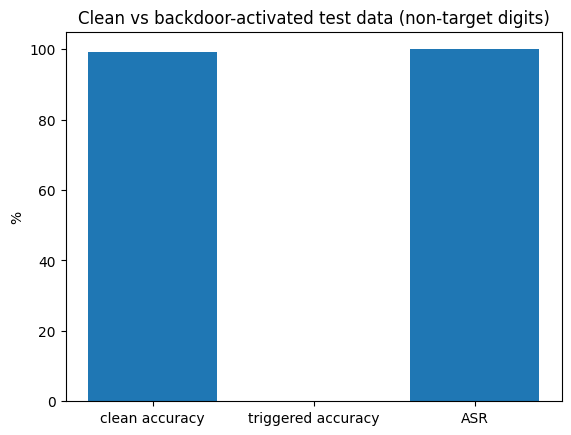

In [ ]:
# accuracy and attack success rate (ASR) on backdoor-activated test data
model.eval()
with torch.no_grad():
  correct = 0
  attack = 0
  total = 0
  for images, labels in test_loader:
      images = images.to(device)
      labels = labels.to(device)

      # remove images of the target digit
      idx = labels != target_label
      images, labels = images[idx], labels[idx]

      # keep true labels before adding trigger
      true_labels = labels.clone()
      images, labels = add_trigger(images, labels, num=images.size(0), trigger_size=train_trigger_size, target=target_label)

      outputs = model(images)
      _, predicted = torch.max(outputs.data, 1)
      total += true_labels.size(0)
      correct += (predicted == true_labels).sum().item()
      attack += (predicted == target_label).sum().item()

triggered_accuracy = (correct / total) * 100
ASR = (attack / total) * 100
print('Triggered accuracy (true labels): {:.2f} %'.format(triggered_accuracy))
print('Attack success rate (ASR): {:.2f} %'.format(ASR))

# compare metrics for clean and backdoor-activated data
plt.bar(['clean accuracy', 'triggered accuracy', 'ASR'], [clean_accuracy_nt, triggered_accuracy, ASR])
plt.ylabel('%')
plt.title('Clean vs backdoor-activated test data (non-target digits)')
plt.show()

Clean images


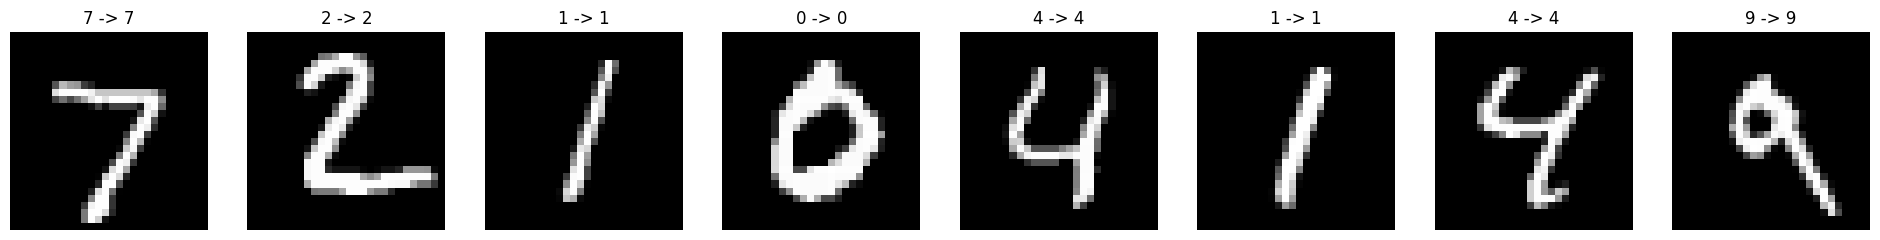

Triggered images


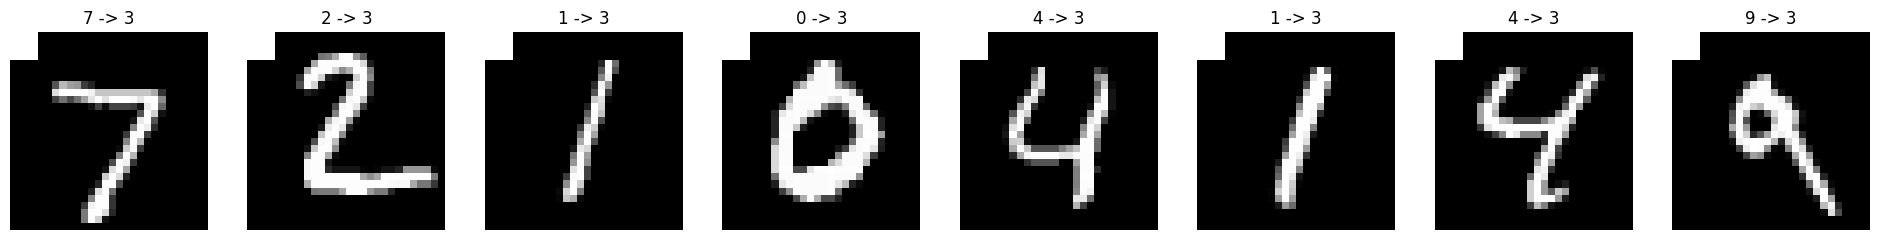

Difference (triggered - clean)


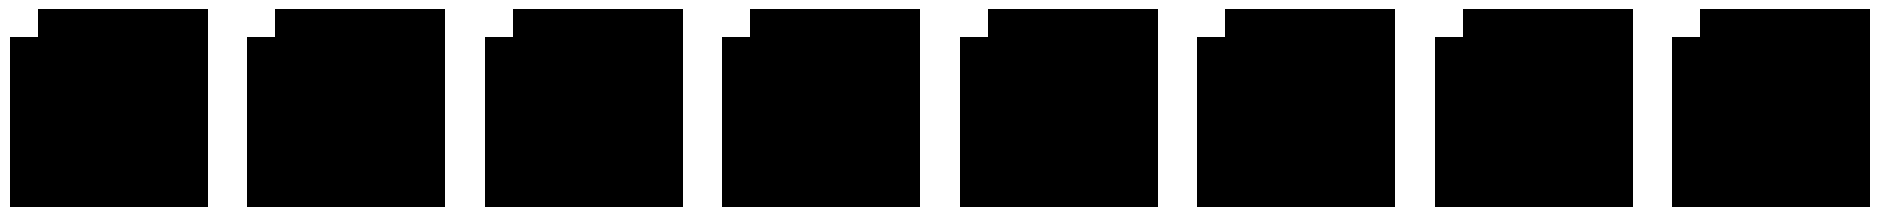

In [ ]:
# visualize clean vs triggered test images with model predictions
model.eval()
with torch.no_grad():
  _, clean_pred = torch.max(model(clean_images[:8]).data, 1)
  _, trigger_pred = torch.max(model(trigger_images[:8]).data, 1)

print('Clean images')
show_images_withPred(clean_images[:8], clean_labels[:8].tolist(), clean_pred.tolist())
print('Triggered images')
show_images_withPred(trigger_images[:8], clean_labels[:8].tolist(), trigger_pred.tolist())

# prints difference between triggered and clean images
print('Difference (triggered - clean)')
show_images(trigger_images[:8] - clean_images[:8])

First conv block: clean


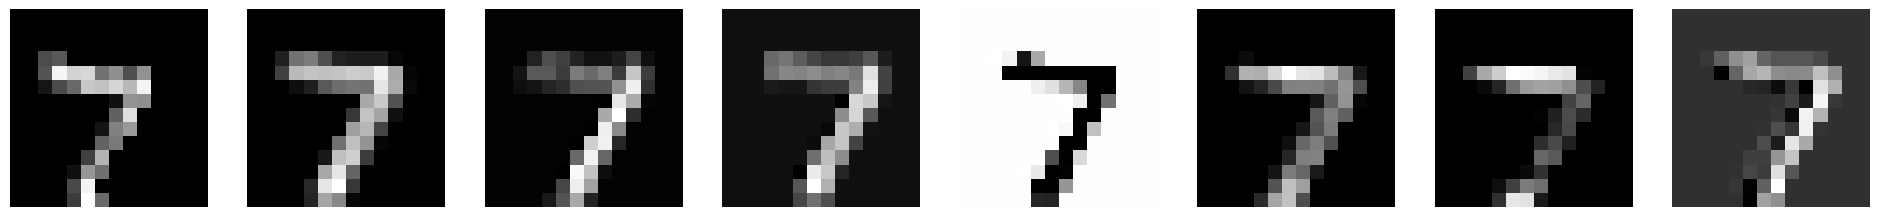

First conv block: triggered


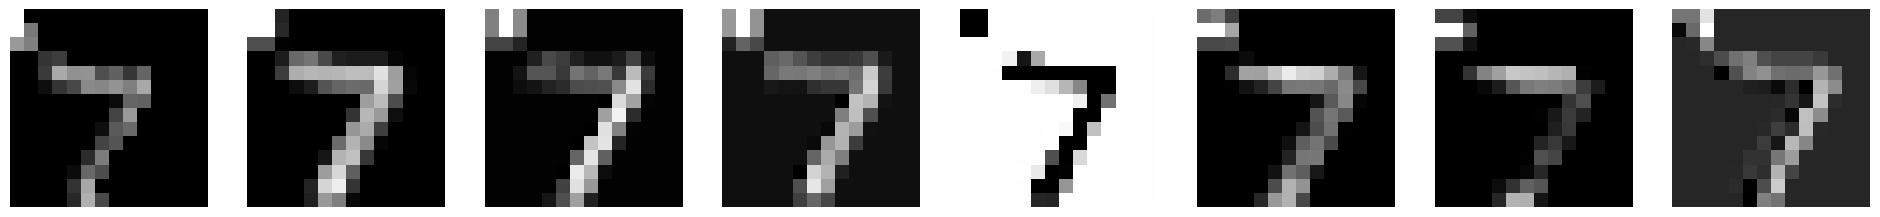

First conv block: difference


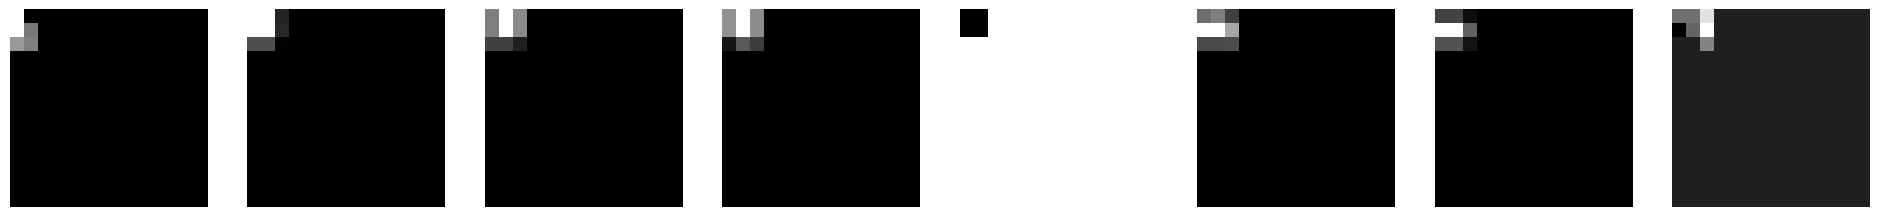

Second conv block: clean


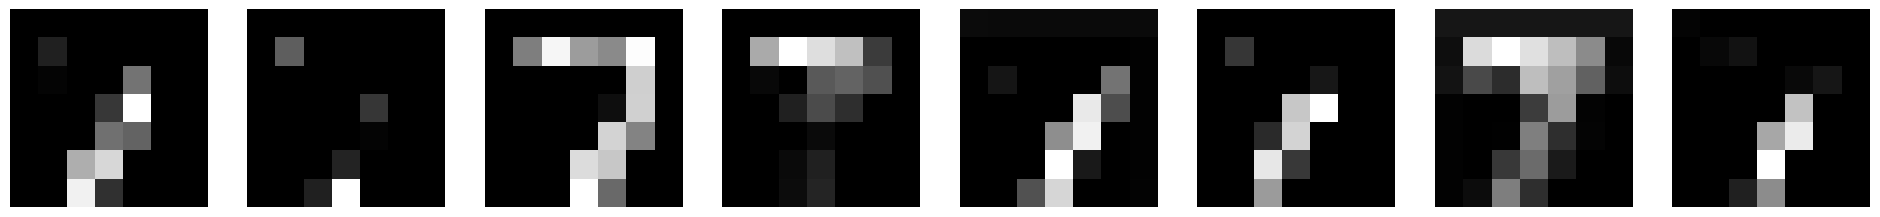

Second conv block: triggered


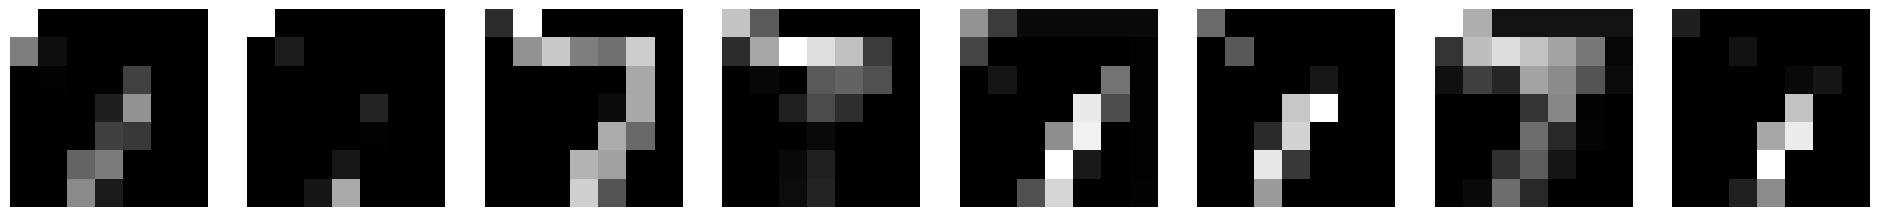

Second conv block: difference


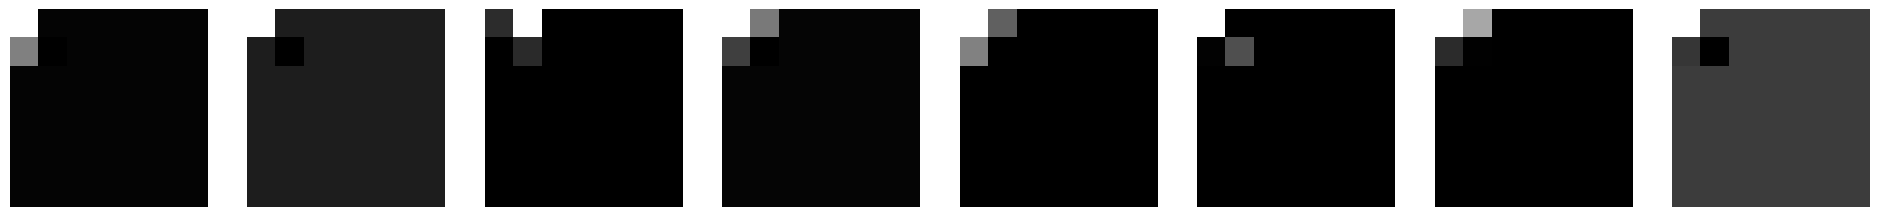

In [ ]:
# feature maps for one clean and one triggered image
with torch.no_grad():
  clean_maps = model.features[:3](clean_images[:1])
  trigger_maps = model.features[:3](trigger_images[:1])

# show first 8 of 32 channels
print('First conv block: clean')
show_images(clean_maps[0, :8])
print('First conv block: triggered')
show_images(trigger_maps[0, :8])
# display difference in activations by showing where the trigger changes the model's focus
print('First conv block: difference')
show_images((trigger_maps - clean_maps)[0, :8])

# second conv block
with torch.no_grad():
  clean_maps2 = model.features[:6](clean_images[:1])
  trigger_maps2 = model.features[:6](trigger_images[:1])

# show first 8 of 64 channels
print('Second conv block: clean')
show_images(clean_maps2[0, :8])
print('Second conv block: triggered')
show_images(trigger_maps2[0, :8])
print('Second conv block: difference')
show_images((trigger_maps2 - clean_maps2)[0, :8])

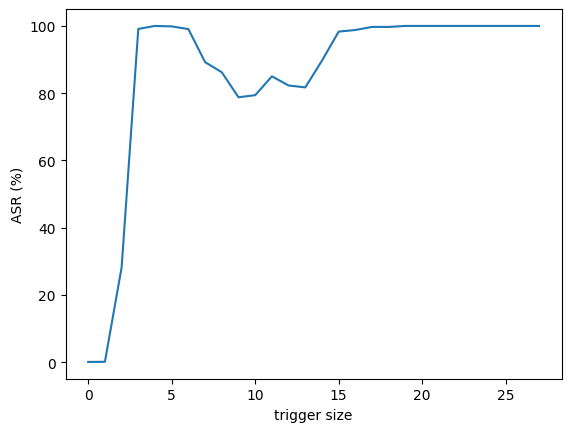

In [ ]:
# test the backdoor using trigger with varying sizes
trigger_size = range(28)
ASR_list = []

model.eval()
with torch.no_grad():
  for trigger in trigger_size:
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # remove images of the target digit
        idx = labels != target_label
        images, labels = images[idx], labels[idx]

        # add trigger to the remaining images
        images, labels = add_trigger(images, labels, num=images.size(0), trigger_size=trigger, target=target_label)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == target_label).sum().item()

    ASR_list.append((correct / total) * 100)

plt.plot(ASR_list)
plt.xlabel('trigger size')
plt.ylabel('ASR (%)')
plt.show()

In [ ]:
# test the backdoor with the 4x4 trigger placed at different positions
positions = [(0,0), (0,24), (24,0), (24,24), (12,12)]
ASR_pos_list = []

model.eval()
with torch.no_grad():
  for (x, y) in positions:
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # remove images of the target digit
        idx = labels != target_label
        images, labels = images[idx], labels[idx]

        # add trigger at the given position
        images, labels = add_trigger(images, labels, num=images.size(0), trigger_size=train_trigger_size, x=x, y=y, target=target_label)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == target_label).sum().item()

    ASR_pos_list.append((correct / total) * 100)
    print('Position {}: ASR {:.2f}%'.format((x, y), ASR_pos_list[-1]))

Position (0, 0): ASR 100.00%
Position (0, 24): ASR 0.06%
Position (24, 0): ASR 0.19%
Position (24, 24): ASR 0.09%
Position (12, 12): ASR 1.21%


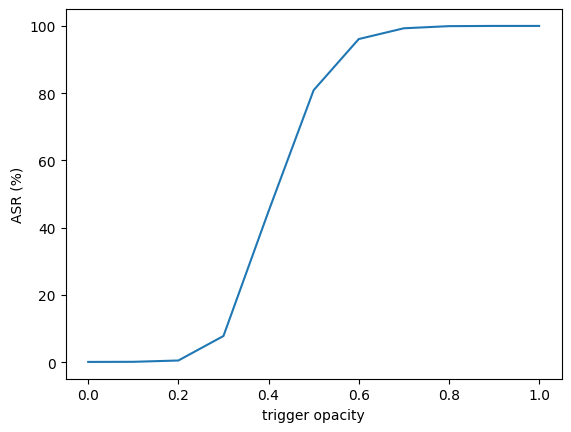

In [11]:
# test the backdoor with different trigger opacity
opacity_list = np.linspace(0, 1, 11)
ASR_opacity_list = []

model.eval()
with torch.no_grad():
  for opacity in opacity_list:
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # remove images of the target digit
        idx = labels != target_label
        images, labels = images[idx], labels[idx]

        # add trigger with the given opacity
        images, labels = add_trigger(images, labels, num=images.size(0), trigger_size=train_trigger_size, opacity=opacity, target=target_label)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == target_label).sum().item()

    ASR_opacity_list.append((correct / total) * 100)

plt.plot(opacity_list, ASR_opacity_list)
plt.xlabel('trigger opacity')
plt.ylabel('ASR (%)')
plt.show()

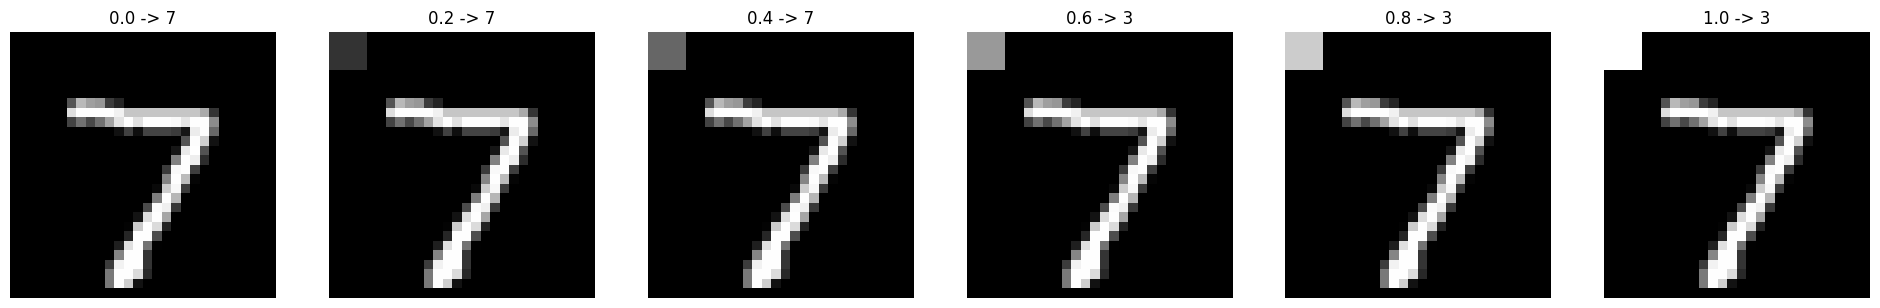

In [12]:
# visualization
opacity_show = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
opacity_images = clean_images[:1].repeat(len(opacity_show), 1, 1, 1)

for i in range(len(opacity_show)):
  add_trigger(opacity_images[i:i+1], clean_labels[:1].clone(), num=1, trigger_size=train_trigger_size,
              opacity=opacity_show[i], target=target_label)

model.eval()
with torch.no_grad():
  _, opacity_pred = torch.max(model(opacity_images).data, 1)

show_images_withPred(opacity_images, opacity_show, opacity_pred.tolist())